# Titanic Dataset Preprocessing Pipeline (Exercises 1 - 7)

### **Exercise 1: Duplicate Detection and Removal**

In [23]:
# Check the initial shape
initial_rows = train.shape[0]
print(f"Initial number of rows: {initial_rows}")

# Identify duplicate rows based on all columns
duplicates = train.duplicated().sum()
print(f"Number of duplicate rows: {duplicates}")

# Remove duplicate rows if any exist
train_cleaned = train.drop_duplicates()

# Verify removal
final_rows = train_cleaned.shape[0]
print(f"Number of rows after duplicate removal: {final_rows}")
print(f"Rows removed: {initial_rows - final_rows}")

Initial number of rows: 891
Number of duplicate rows: 0
Number of rows after duplicate removal: 891
Rows removed: 0


### **Exercise 2: Handling Missing Values**

In [24]:
# Identify columns with missing values
missing_info = train_cleaned.isnull().sum()
print("Missing values per column:")
print(missing_info[missing_info > 0])

# 1. Fill 'Embarked' (categorical) with its mode
embarked_mode = train_cleaned['Embarked'].mode()[0]
train_cleaned['Embarked'] = train_cleaned['Embarked'].fillna(embarked_mode)

# 2. Fill 'Age' (continuous) with its median
age_median = train_cleaned['Age'].median()
train_cleaned['Age'] = train_cleaned['Age'].fillna(age_median)

# 3. For 'Cabin', because too many values are missing, we will fill with a constant label 'Unknown'
train_cleaned['Cabin'] = train_cleaned['Cabin'].fillna('Unknown')

# Verify that there are no remaining missing values
print("\nMissing values after treatment:")
print(train_cleaned.isnull().sum())

Missing values per column:
Age         177
Cabin       687
Embarked      2
dtype: int64

Missing values after treatment:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Cabin          0
Embarked       0
dtype: int64


### **Exercise 3: Feature Engineering**

In [25]:
# 1. Create Family Size feature
train_cleaned['FamilySize'] = train_cleaned['SibSp'] + train_cleaned['Parch'] + 1

# 2. Extract Title from the Name column
train_cleaned['Title'] = train_cleaned['Name'].str.extract(' ([A-Za-z]+)\.', expand=False)

# Simplify titles to avoid rare titles
rare_titles = ['Dr', 'Rev', 'Col', 'Major', 'Mlle', 'Countess', 'Ms', 'Lady', 'Jonkheer', 'Don', 'Mme', 'Capt', 'Sir', 'Sir', 'Lady']
train_cleaned['Title'] = train_cleaned['Title'].replace(rare_titles, 'Rare')

# Preview engineered features
display(train_cleaned[['Name', 'Title', 'FamilySize']].head())
print(train_cleaned['Title'].value_counts())

<>:5: SyntaxWarning: invalid escape sequence '\.'
<>:5: SyntaxWarning: invalid escape sequence '\.'
/tmp/ipykernel_1072/1145252740.py:5: SyntaxWarning: invalid escape sequence '\.'
  train_cleaned['Title'] = train_cleaned['Name'].str.extract(' ([A-Za-z]+)\.', expand=False)


,Name,Title,FamilySize
0,"Braund, Mr. Owen Harris",Mr,2
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Mrs,2
2,"Heikkinen, Miss. Laina",Miss,1
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Mrs,2
4,"Allen, Mr. William Henry",Mr,1


Title
Mr        517
Miss      182
Mrs       125
Master     40
Rare       27
Name: count, dtype: int64


### **Exercise 4: Outlier Detection and Handling**

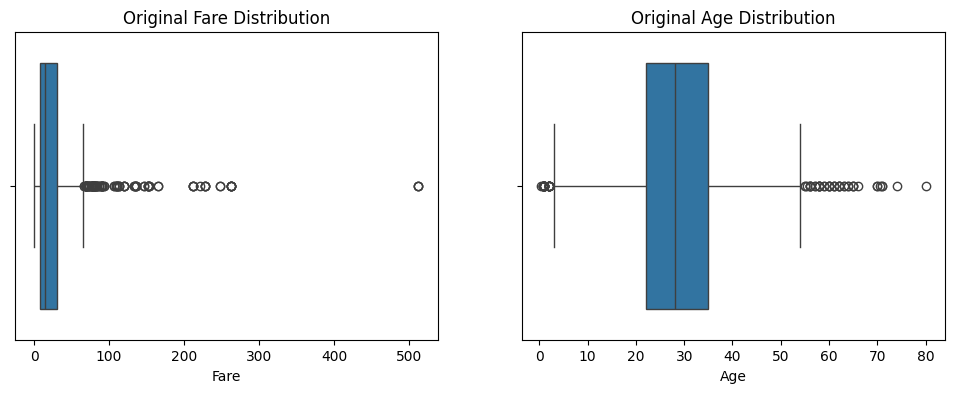

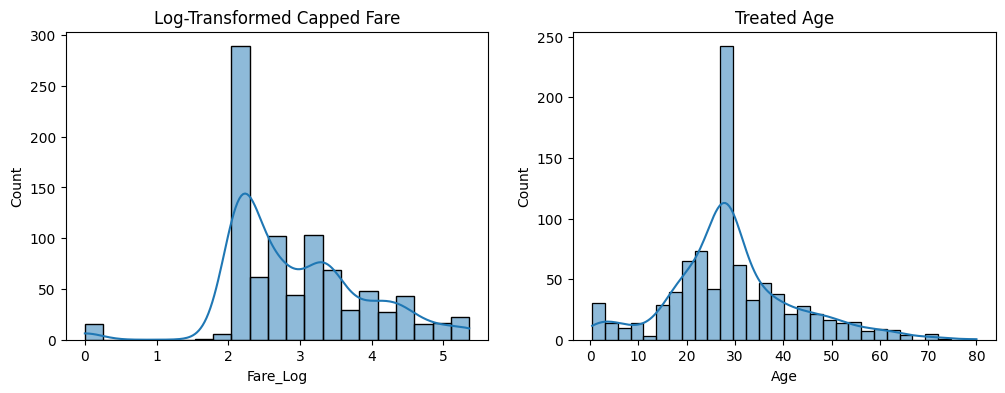

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Plot original distributions to visualize outliers
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(ax=axes[0], x=train_cleaned['Fare']).set_title('Original Fare Distribution')
sns.boxplot(ax=axes[1], x=train_cleaned['Age']).set_title('Original Age Distribution')
plt.show()

# 1. Quantile Capping (Fare) at 98th percentile
fare_cap = train_cleaned['Fare'].quantile(0.98)
train_cleaned['Fare_Capped'] = train_cleaned['Fare'].clip(upper=fare_cap)

# 2. Log Transformation (Fare) to handle remaining skew
train_cleaned['Fare_Log'] = np.log1p(train_cleaned['Fare_Capped'])

# Plot treated distributions
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(ax=axes[0], x=train_cleaned['Fare_Log'], kde=True).set_title('Log-Transformed Capped Fare')
sns.histplot(ax=axes[1], x=train_cleaned['Age'], kde=True).set_title('Treated Age')
plt.show()

### **Exercise 5: Data Standardization and Normalization**

In [27]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# StandardScaler for normally distributed Age
scaler_std = StandardScaler()
train_cleaned['Age_Scaled'] = scaler_std.fit_transform(train_cleaned[['Age']])

# MinMaxScaler for skewed / bounded Fare
scaler_minmax = MinMaxScaler()
train_cleaned['Fare_Scaled'] = scaler_minmax.fit_transform(train_cleaned[['Fare_Log']])

# Verify Scaling metrics
display(train_cleaned[['Age', 'Age_Scaled', 'Fare_Log', 'Fare_Scaled']].describe())

,Age,Age_Scaled,Fare_Log,Fare_Scaled
count,891.000000,8.910000e+02,891.000000,891.000000
mean,29.361582,2.272780e-16,2.957075,0.551881
std,13.019697,1.000562e+00,0.954565,0.178151
min,0.420000,-2.224156e+00,0.000000,0.000000
25%,22.000000,-5.657365e-01,2.187218,0.408202
50%,28.000000,-1.046374e-01,2.737881,0.510972
75%,35.000000,4.333115e-01,3.465736,0.646813
max,80.000000,3.891554e+00,5.358177,1.000000


### **Exercise 6: Feature Encoding**

In [28]:
# 1. One-Hot Encoding for nominal columns: 'Sex', 'Embarked', 'Title'
train_encoded = pd.get_dummies(train_cleaned, columns=['Sex', 'Embarked', 'Title'], drop_first=True)

# Display the columns after encoding
print("Columns in dataframe after One-Hot Encoding nominal variables:")
print(train_encoded.columns.tolist())

Columns in dataframe after One-Hot Encoding nominal variables:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'FamilySize', 'Fare_Capped', 'Fare_Log', 'Age_Scaled', 'Fare_Scaled', 'Sex_male', 'Embarked_Q', 'Embarked_S', 'Title_Miss', 'Title_Mr', 'Title_Mrs', 'Title_Rare']


### **Exercise 7: Data Transformation for Age Feature**

In [29]:
# 1. Create life stages age groups using pd.cut()
bins = [0, 12, 18, 60, 100]
labels = ['Child', 'Teen', 'Adult', 'Senior']
train_encoded['Age_Group'] = pd.cut(train_encoded['Age'], bins=bins, labels=labels)

# 2. Apply One-Hot Encoding on Age_Group
train_final = pd.get_dummies(train_encoded, columns=['Age_Group'], drop_first=False)

# Display preview of final features
display(train_final.head(5))

,PassengerId,Survived,Pclass,Name,Age,SibSp,Parch,Ticket,Fare,Cabin,...,Embarked_Q,Embarked_S,Title_Miss,Title_Mr,Title_Mrs,Title_Rare,Age_Group_Child,Age_Group_Teen,Age_Group_Adult,Age_Group_Senior
0,1,0,3,"Braund, Mr. Owen Harris",22.0,1,0,A/5 21171,7.2500,Unknown,...,False,True,False,True,False,False,False,False,True,False
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",38.0,1,0,PC 17599,71.2833,C85,...,False,False,False,False,True,False,False,False,True,False
2,3,1,3,"Heikkinen, Miss. Laina",26.0,0,0,STON/O2. 3101282,7.9250,Unknown,...,False,True,True,False,False,False,False,False,True,False
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",35.0,1,0,113803,53.1000,C123,...,False,True,False,False,True,False,False,False,True,False
4,5,0,3,"Allen, Mr. William Henry",35.0,0,0,373450,8.0500,Unknown,...,False,True,False,True,False,False,False,False,True,False
